In [89]:
from sklearn.datasets import load_digits
import tensorflow.keras as keras
import tensorflow as uf

In [90]:
data = load_digits()
X = data["data"]
y = data["target"]

In [91]:
from sklearn.model_selection import train_test_split

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

In [93]:
X_train.shape

(1347, 64)

In [94]:
X_train[0]

array([ 0.,  0.,  7., 15., 15.,  5.,  0.,  0.,  0.,  6., 16., 12., 16.,
       12.,  0.,  0.,  0.,  1.,  7.,  0., 16., 10.,  0.,  0.,  0.,  0.,
        0., 10., 15.,  0.,  0.,  0.,  0.,  0.,  1., 16.,  7.,  0.,  0.,
        0.,  0.,  0., 10., 13.,  1.,  5.,  1.,  0.,  0.,  0., 12., 12.,
       13., 15.,  3.,  0.,  0.,  0., 10., 16., 13.,  3.,  0.,  0.])

In [95]:
import matplotlib.pyplot as pt

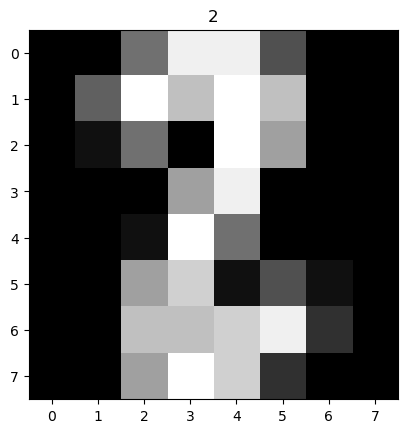

In [96]:
pt.imshow(X_train[0].reshape(8, 8), cmap="gray")
pt.title(y_train[0]);

In [97]:
from tensorflow.keras import layers
from keras import Sequential

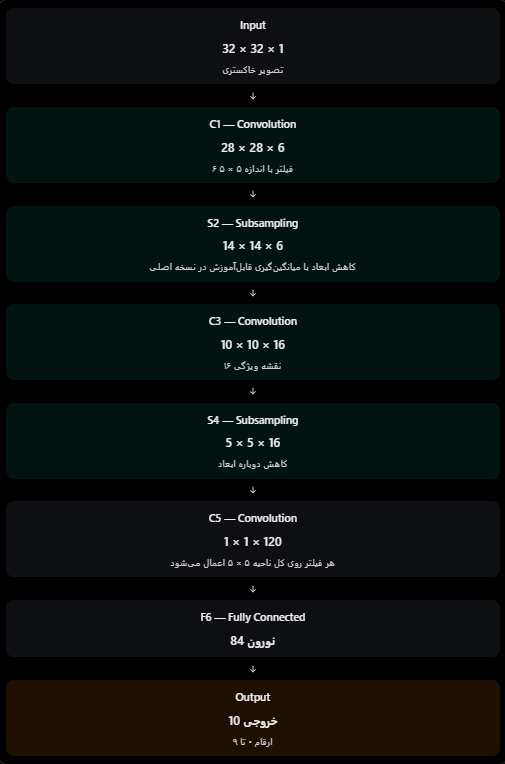

In [98]:
X_train.shape

(1347, 64)

In [99]:
X_train = X_train.reshape(-1,8,8,1).astype('float32') / 255.0
X_test = X_test.reshape(-1,8,8,1).astype('float32') / 255.0

In [100]:
# model = Sequential(
#     [
#         # keras.Input(shape=(32, 32, 1), name="input"),
#         layers.Conv2D(6, (2, 2), padding="same", activation="relu", name="C1"),
#         layers.MaxPooling2D((2, 2), name="C2"),
#         layers.Conv2D(16, (2, 2), padding="same", activation="relu", name="C3"),
#         layers.MaxPooling2D((2, 2), name="C4"),
#         layers.Conv2D(120, (2, 2), padding="valid", activation="relu", name="C5"),
#         layers.Flatten(),
#         layers.Dense(84, activation="relu", name="C6"),
#         layers.Dense(10, activation="softmax", name="C7"),
#     ],
#     name="LeNet5",
# )

In [101]:
model = Sequential(
    [
        # keras.Input(shape=(8, 8, 1), name="input"),
        layers.Conv2D(
            filters=6, kernel_size=(2, 2), padding="same", activation="relu", name="C1"
        ),
        # layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2), name="C2"),
        # layers.Dropout(0.2),
        layers.Conv2D(filters=16, kernel_size=(2, 2), name="C3"),
        # layers.BatchNormalization(), #این لایه خروجی لایهٔ قبلی را نرمال‌سازی می‌کند تا آموزش شبکه پایدارتر و سریع‌تر شود.
        layers.MaxPooling2D((2, 2), name="C4"),
        # layers.Dropout(0.1),
        layers.Conv2D(120, (5, 5), padding="same", activation="relu", name="C5"),
        layers.Flatten(),
        layers.Dense(84, activation="relu", name="C6"),
        # layers.Dropout(0.2),
        # layers.Dense(84, activation="relu", name="C7"),
        # layers.Dropout(0.1),
        # layers.Dense(60, activation="relu", name="C8"),
        # layers.Dropout(0.3),
        # layers.Dense(60, activation="relu", name="C9"),
        # layers.Dropout(0.2),
        layers.Dense(10, activation="softmax", name="C10"),
    ],
    name='ramin'
    
)

In [102]:
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [103]:
history = model.fit(X_train, y_train, batch_size=64, epochs=100, validation_split=0.2 , verbose= 1)

Epoch 1/100


17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.0947 - loss: 2.3029 - val_accuracy: 0.0778 - val_loss: 2.3031
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1031 - loss: 2.3022 - val_accuracy: 0.0778 - val_loss: 2.3033
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1337 - loss: 2.3016 - val_accuracy: 0.1037 - val_loss: 2.3035
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1096 - loss: 2.3002 - val_accuracy: 0.0778 - val_loss: 2.3032
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1281 - loss: 2.2979 - val_accuracy: 0.1556 - val_loss: 2.3013
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2368 - loss: 2.2919 - val_accuracy: 0.2148 - val_loss: 2.2947
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1597 - loss: 2.2817 - val_accuracy: 0.1704 - val_loss: 2.2811
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2284 - loss: 2.2561 - val_accuracy: 0.1778 - val_loss: 2.

In [104]:
model.summary()

Model: "ramin"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ C1 (Conv2D)                     │ (None, 8, 8, 6)        │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C2 (MaxPooling2D)               │ (None, 4, 4, 6)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 3, 3, 16)       │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C4 (MaxPooling2D)               │ (None, 1, 1, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Conv2D)                     │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C10 (Dense)                     │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,694 (698.03 KB)

 Trainable params: 59,564 (232.67 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 119,130 (465.36 KB)

In [105]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [106]:
model.evaluate(X_test, y_test)

 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7812 - loss: 0.4367

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8356 - loss: 0.5680 


[0.5680261850357056, 0.8355555534362793]

In [107]:
model.predict(X_test[5].reshape(1,8,8,1)).argmax()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


np.int64(0)

In [108]:
y_test[5]

np.int64(0)

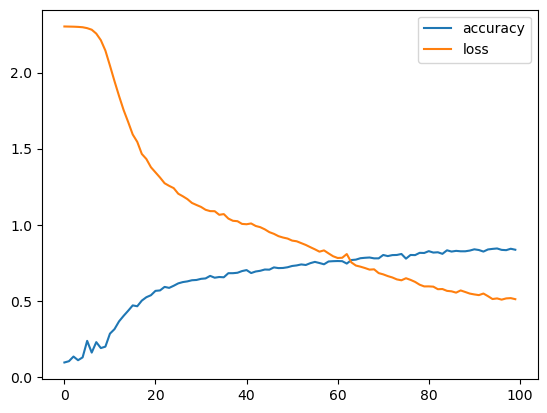

In [109]:
pt.plot(history.history['accuracy'])
pt.plot(history.history['loss'])
pt.legend(['accuracy','loss'])

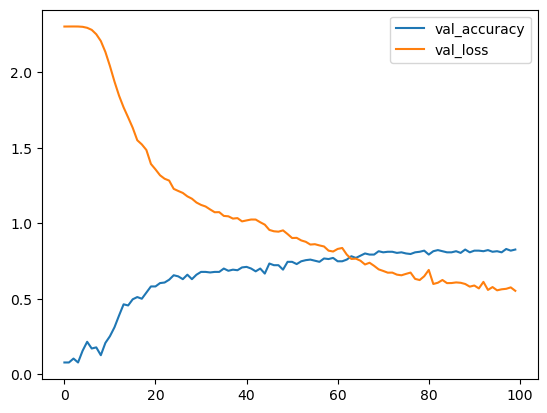

In [110]:
pt.plot(history.history['val_accuracy'])
pt.plot(history.history['val_loss'])
pt.legend(['val_accuracy','val_loss'])